In [1]:
#1.1
import pandas as pd

pd.read_csv("C:/Users/santi/OneDrive/Documents/ML/TP1/data/raw/casas_dev.csv").sample(10)


,precio,tipo,Área,metros_cubiertos,unidades,ambientes,pisos,pileta,lat,lon,edad
736,179564.462107,depto,705.929484,678.506028,sqft,6,NaN,False,40.720451,-73.951720,6.881442
1085,213683.630138,depto,749.403950,719.333011,sqft,10,NaN,False,40.716633,-73.964515,4.369698
287,50841.275642,casa,226.735520,118.954124,m2,9,3.0,True,-34.720172,-58.256316,44.287044
231,208417.555352,depto,670.517842,656.318703,sqft,5,NaN,False,40.818100,-74.015324,3.557413
994,NaN,ph,1282.772429,1131.030857,sqft,9,1.0,False,40.693967,-74.035189,25.740559
1466,140565.301099,depto,772.378967,735.824808,sqft,7,NaN,False,40.797560,-73.967476,5.085125
55,7366.432257,casa,200.991803,126.021678,m2,10,3.0,False,-34.702094,-58.285130,12.110533
129,27181.704274,casa,253.855221,146.590804,m2,10,3.0,True,-34.732260,-58.291188,29.579961
1571,202408.751587,depto,731.902580,704.934263,sqft,6,NaN,False,40.812054,-74.047634,3.439496
493,15039.516730,depto,71.304037,70.663345,m2,6,NaN,False,-34.774993,-58.211924,11.252211


1.1
Puedo obvservar que hay muchos datos que tendria que modificar para su analisis, voy a ir nombrando los problemas columna por columna.

Los precios, la mayoria parecen ser consistentes, pero varios tienen precios absurdos, por ejemplo que un departamento vale $0.

El Area y metros cubiertos lo interpreto como el area de la propiedad, y los metros cubiertos por construccion. Tambien puede servir para encontrar errores, si area > metros_cubiertos entonces algo anda mal.

Las unidades habria que unificarlas a m2 o a sqft, ya que el modelo que vayamos a usar va a interpreta las areas como si fueran de la misma unidad.

En pisos, cuando el tipo de propiedad es un depto queda en NaN, tal vez convendria cargarle el valor 0 en ese caso. Y en el caso de las edades tambien, tal vez NaN significa que son propiedades a estrenar, tampoco me gusta que tengan decimales en edad, raro de interpretar.

C:\Users\santi\AppData\Local\Temp\ipykernel_6768\665944184.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="unidades", loc="upper right")


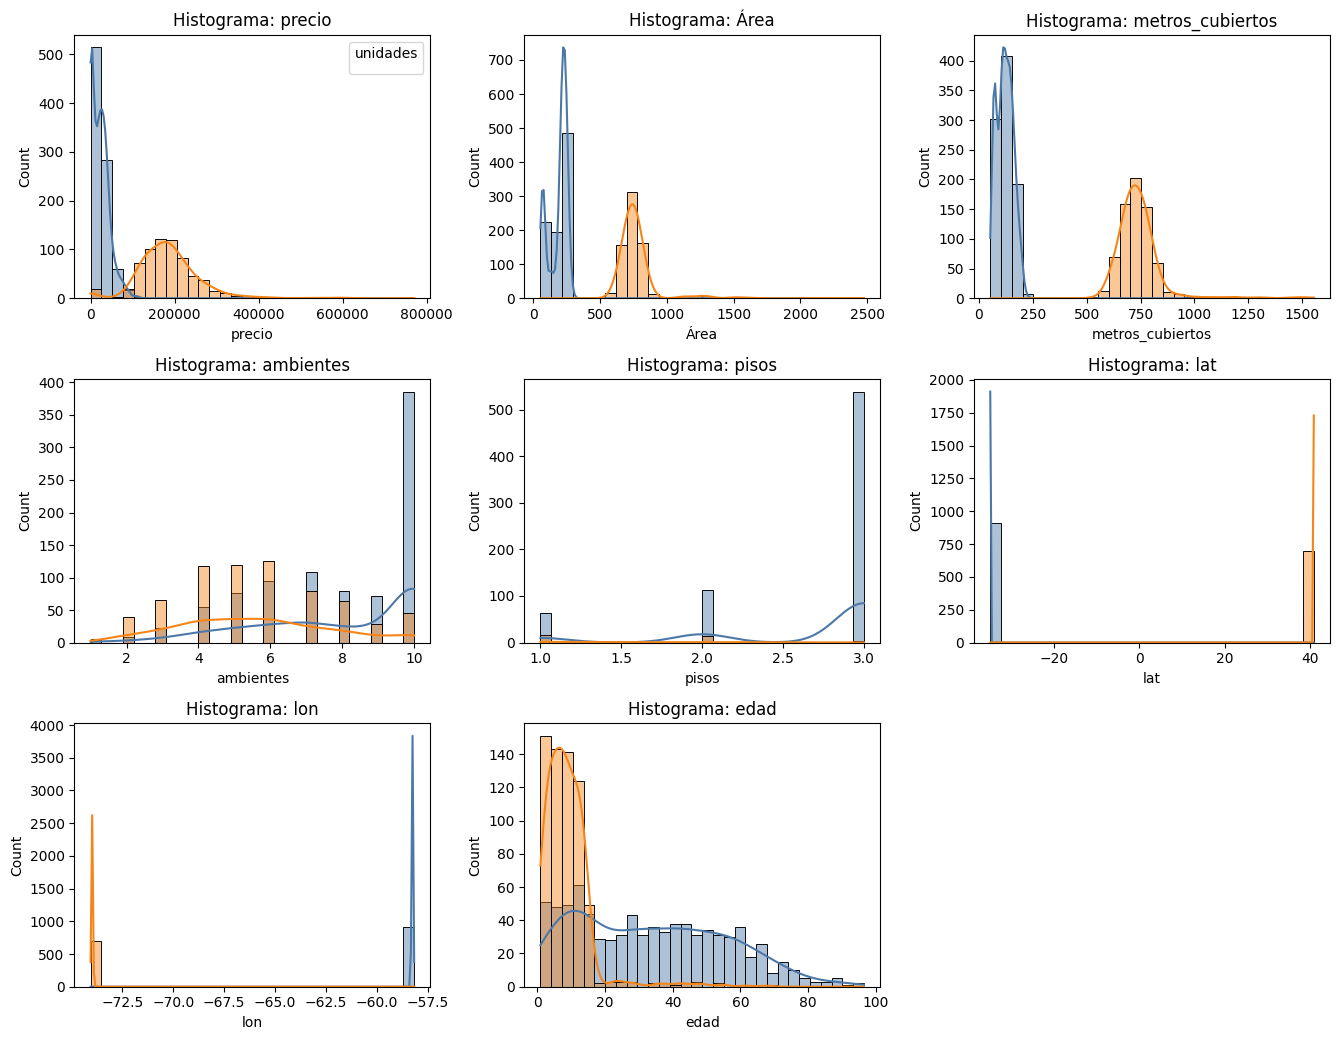

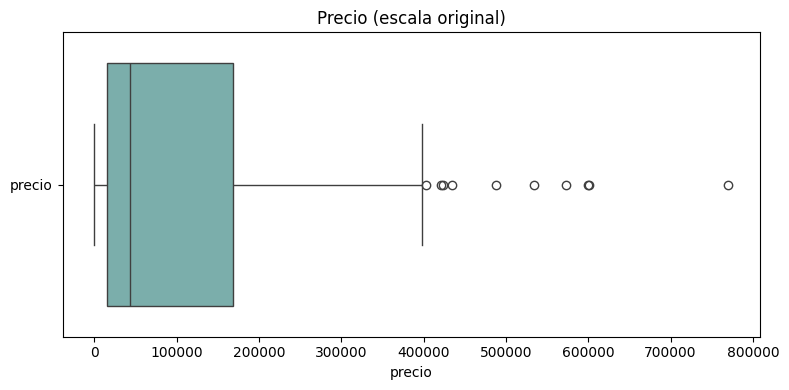

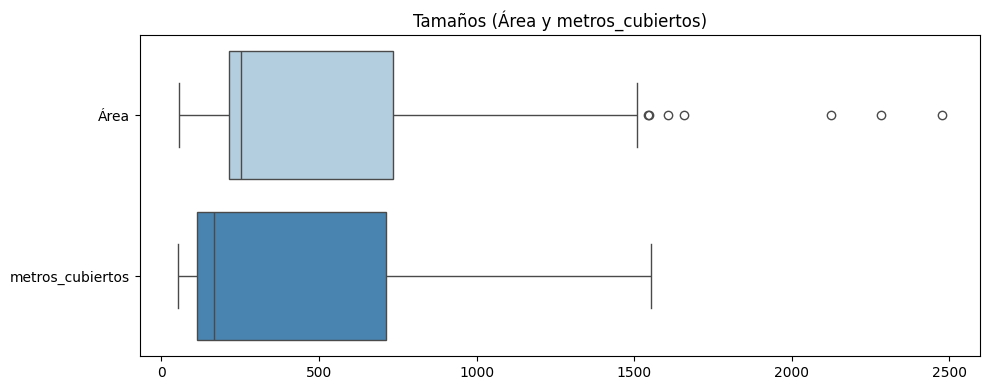

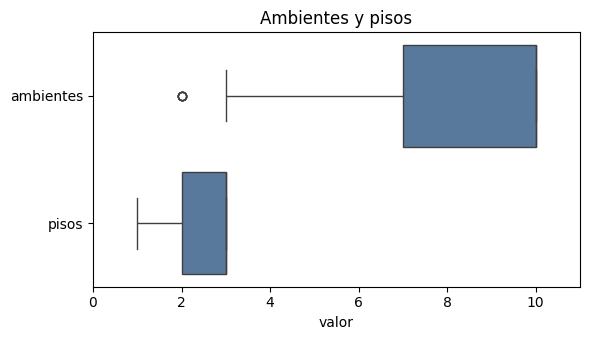

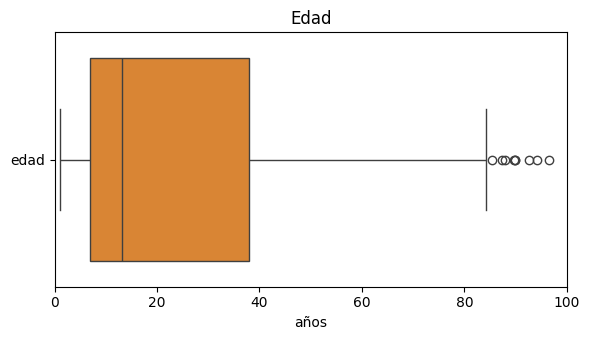

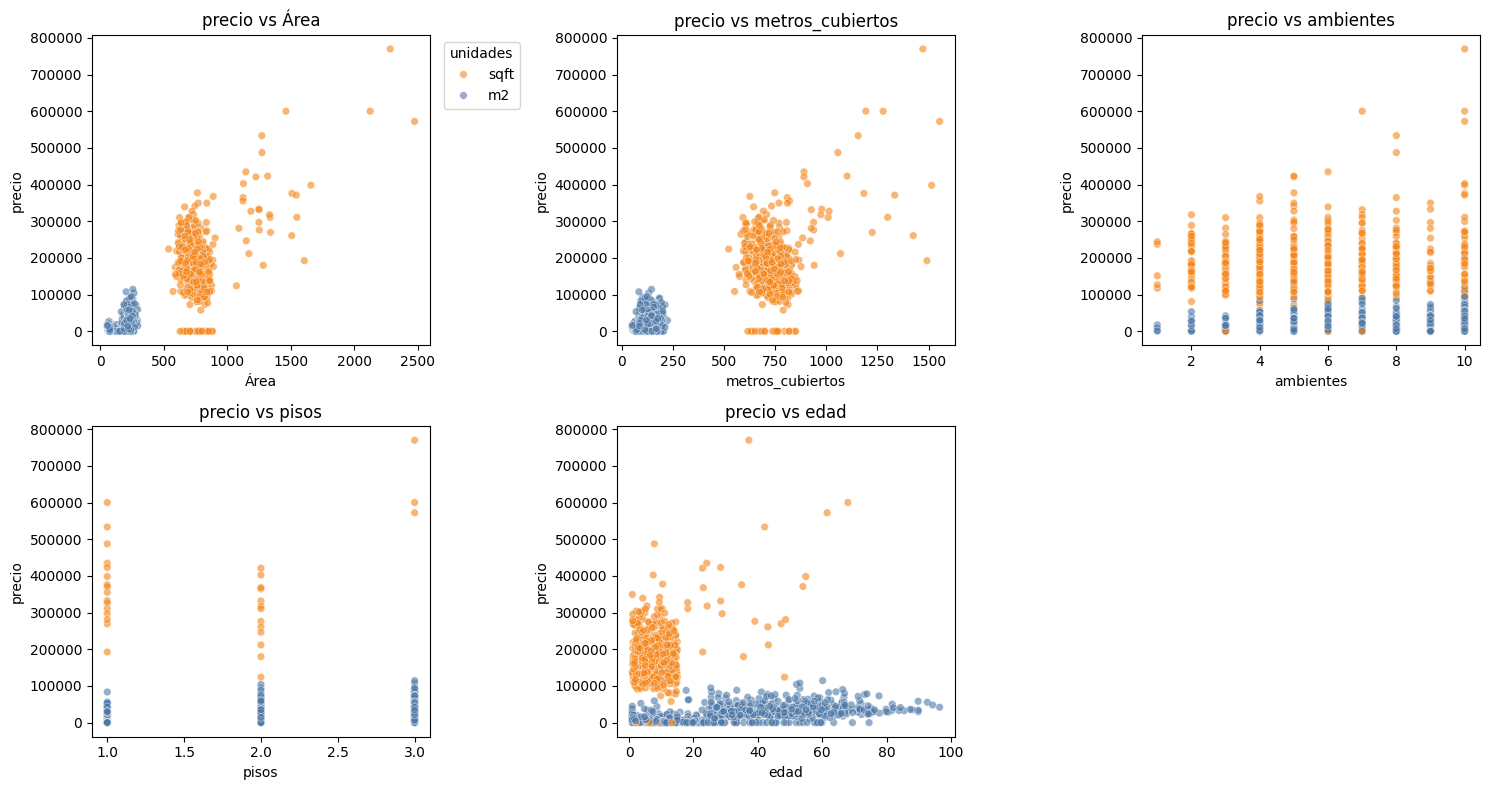

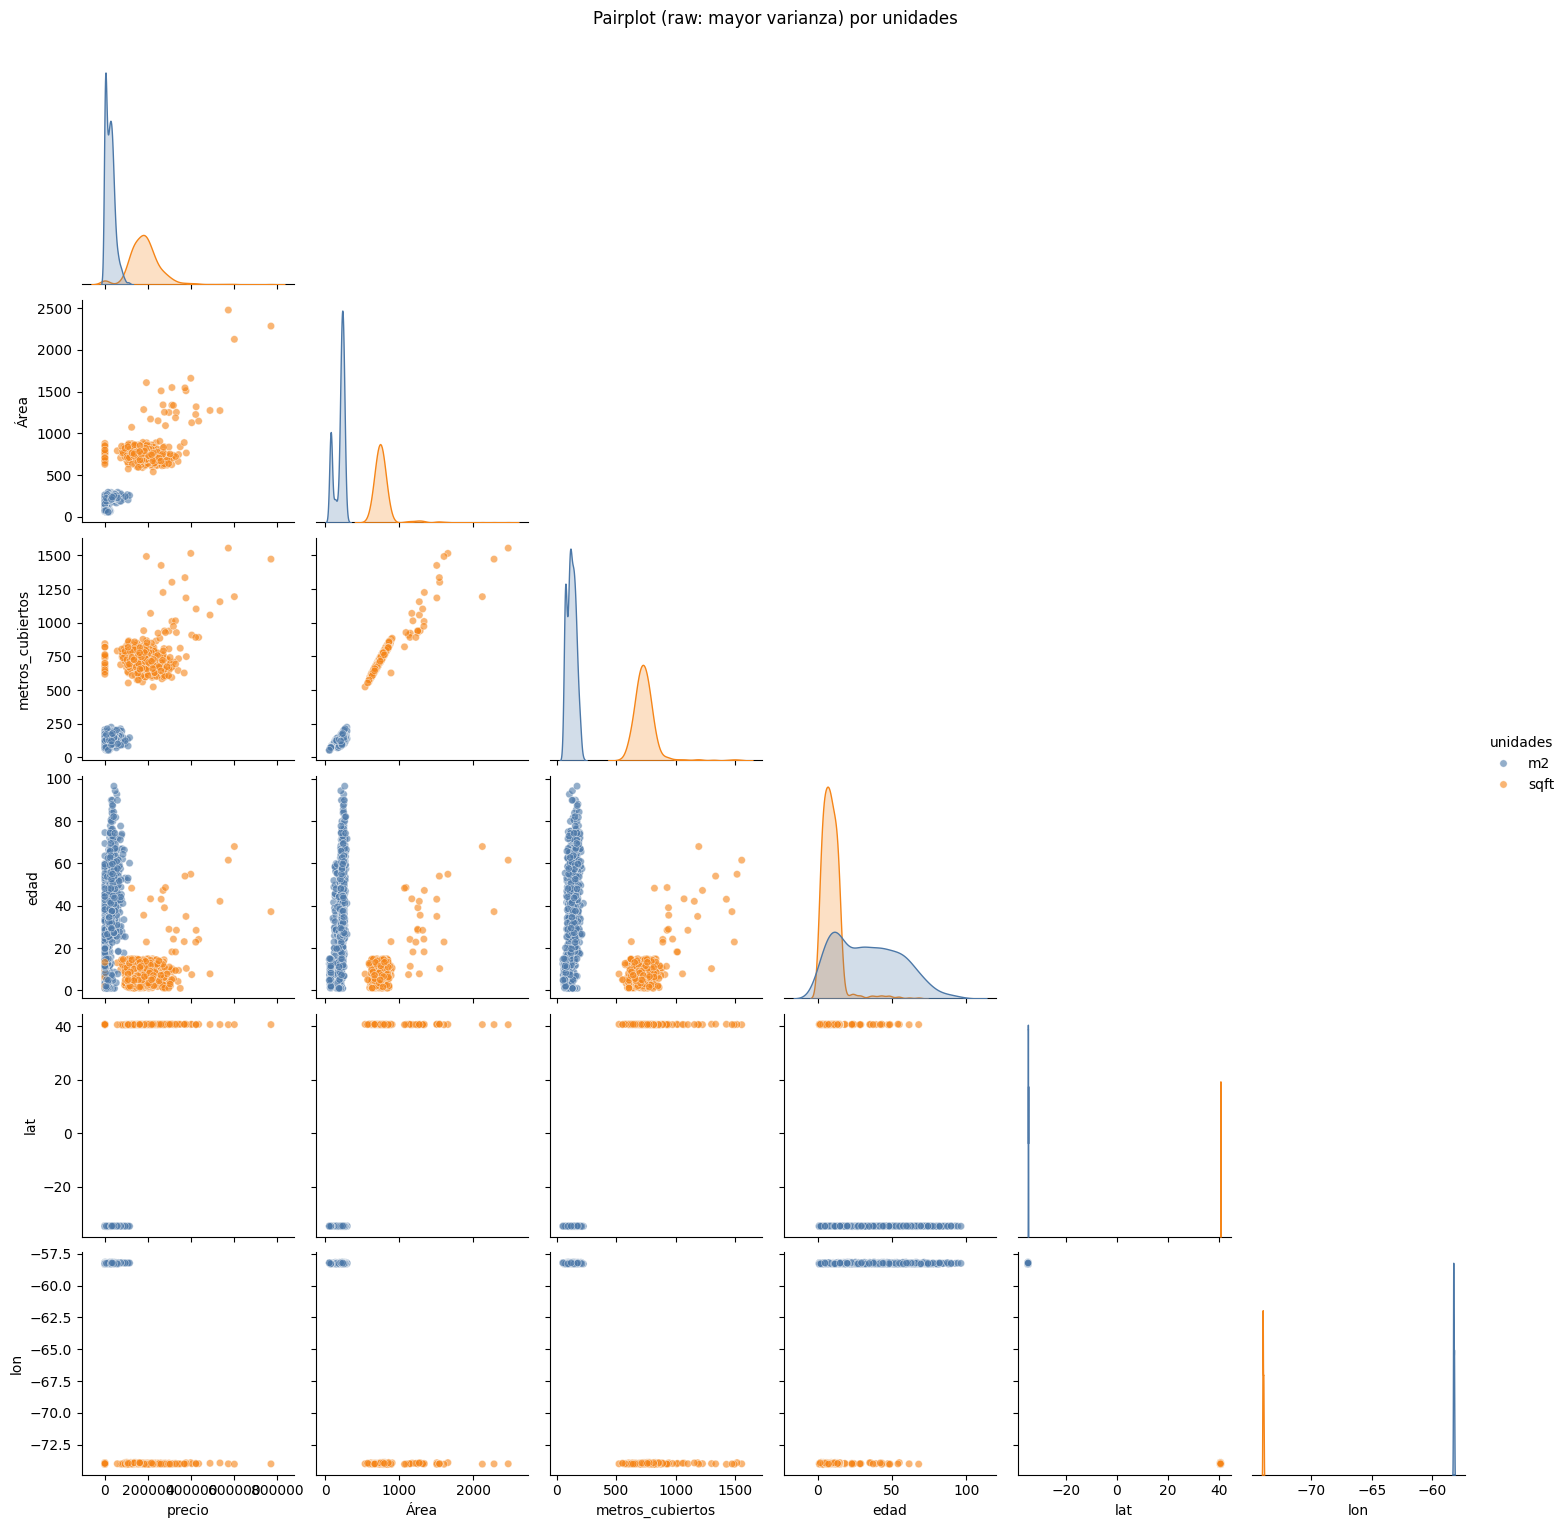

In [2]:
# 1.2 - Gráficos con datos crudos (data/raw/casas_dev.csv)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv("../data/raw/casas_dev.csv")

# Columnas numéricas
num_cols_raw = df_raw.select_dtypes(include=[np.number]).columns.tolist()
plot_df_raw = df_raw[num_cols_raw].dropna()

# Histograma(s) coloreados por unidades (m2 vs sqft si existe)
cols = num_cols_raw
n = len(cols)
cols_per_row = 3
rows = int(np.ceil(n / cols_per_row))
plt.figure(figsize=(cols_per_row * 4.5, rows * 3.5))
for i, c in enumerate(cols, 1):
    plt.subplot(rows, cols_per_row, i)
    if "unidades" in df_raw.columns:
        palette = {"m2": "#4C78A8", "sqft": "#F58518"}
        sns.histplot(
            data=df_raw,
            x=c,
            hue="unidades",
            bins=30,
            kde=True,
            multiple="layer",
            alpha=0.45,
            palette=palette
        )
        # Mostrar la leyenda solo en el primer subplot
        if i == 1:
            plt.legend(title="unidades", loc="upper right")
        else:
            ax = plt.gca()
            leg = ax.get_legend()
            if leg:
                leg.remove()
    else:
        sns.histplot(df_raw[c].dropna(), kde=True, bins=30, color="#4C78A8")

    plt.title(f"Histograma: {c}")
    plt.xlabel(c)
plt.tight_layout()
plt.show()

# Boxplots separados por grupos (precio, tamaños, otras)

def available(cols):
    return [c for c in cols if c in df_raw.columns]

price_col = available(["precio"])
size_cols = available(["Área", "metros_cubiertos"])
# Separar ambientes/pisos de edad
low_mag_cols = available(["ambientes", "pisos"])
age_cols = available(["edad"])

# Precio
if price_col:
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    sns.boxplot(data=df_raw[price_col], orient="h", ax=ax, color="#72B7B2")
    ax.set_title("Precio (escala original)")
    ax.set_xlabel("precio")
    plt.tight_layout()
    plt.show()

# Tamaños (Área y metros_cubiertos)
if size_cols:
    df_size = df_raw[size_cols].dropna()
    fig, ax = plt.subplots(1, 1, figsize=(10, 4))
    sns.boxplot(data=df_size, orient="h", ax=ax, palette="Blues")
    ax.set_title("Tamaños (Área y metros_cubiertos)")
    plt.tight_layout()
    plt.show()

# Ambientes y pisos
if low_mag_cols:
    df_low = df_raw[low_mag_cols].dropna()
    fig, ax = plt.subplots(1, 1, figsize=(6, 3.5))
    sns.boxplot(data=df_low, orient="h", ax=ax, color="#4C78A8")
    ax.set_title("Ambientes y pisos")
    ax.set_xlabel("valor")
    ax.set_xlim(0, 11)
    plt.tight_layout()
    plt.show()

# Edad
if age_cols:
    df_age = df_raw[age_cols].dropna()
    fig, ax = plt.subplots(1, 1, figsize=(6, 3.5))
    sns.boxplot(data=df_age, orient="h", ax=ax, color="#F58518")
    ax.set_title("Edad")
    ax.set_xlabel("años")
    ax.set_xlim(0, 100)
    plt.tight_layout()
    plt.show()

# Scatter plots contra precio
if "precio" in df_raw.columns:
    candidates = [c for c in ["Área", "metros_cubiertos", "ambientes", "pisos", "edad"] if c in df_raw.columns]
    n = len(candidates)
    if n > 0:
        cols_per_row = 3
        rows = int(np.ceil(n / cols_per_row))
        plt.figure(figsize=(cols_per_row * 5, rows * 4))

        palette = {"m2": "#4C78A8", "sqft": "#F58518"}

        axes = []
        for i, c in enumerate(candidates, 1):
            ax = plt.subplot(rows, cols_per_row, i)
            axes.append(ax)
            sns.scatterplot(
                data=df_raw, x=c, y="precio",
                hue="unidades", palette=palette, alpha=0.6, s=30,
                legend=(i == 1), ax=ax
            )
            if i == 1:
                ax.legend(title="unidades", loc="upper left", bbox_to_anchor=(1.02, 1.0))
            ax.set_xlabel(c)
            ax.set_ylabel("precio")
            ax.set_title(f"precio vs {c}")

        plt.tight_layout()
        plt.show()

# Pairplot de columnas con mayor varianza, coloreado por unidades (m2 vs sqft)
variance = plot_df_raw.var(numeric_only=True).sort_values(ascending=False)
var_cols = variance.head(min(6, len(variance))).index.tolist()
pp_cols = [c for c in var_cols if c in df_raw.columns]

if len(pp_cols) >= 2:
    if "unidades" in df_raw.columns:
        palette = {"m2": "#4C78A8", "sqft": "#F58518"}
        df_pp = df_raw.dropna(subset=pp_cols + ["unidades"]).copy()
        g = sns.pairplot(
            df_pp,
            vars=pp_cols,
            hue="unidades",
            corner=True,
            diag_kind="kde",
            plot_kws={"alpha": 0.6, "s": 28},
            palette=palette
        )
        g.fig.suptitle("Pairplot (raw: mayor varianza) por unidades", y=1.02)
        plt.show()
else:
    print("Pairplot no disponible (columnas insuficientes)")

### 1.2 - Conclusiones rápidas (datos crudos)

- Precio, Área y metros_cubiertos muestran sesgo a la derecha y outliers altos;
- Al colorear por unidades, m2 y sqft quedan bien diferenciados y operan en escalas distintas;
- Scatter precio vs Área/metros_cubiertos: relación positiva clara; metros_cubiertos parece asociarse levemente mejor con precio.
- Ambientes crece con el tamaño y se relaciona de forma moderada con precio; pisos muestra efecto débil; edad sugiere leve relación negativa con precio.
- El pairplot confirma alta correlación entre Área y metros_cubiertos y correlación moderada con precio; el resto de numéricas aportan menos señal directa.
- Se observan dos grupos geográficos (lat/lon) con patrones distintos (p. ej., NYC vs AMBA), potencial fuente de heterogeneidad.
- Hay faltantes y algunos valores atípicos (p. ej., precio ≤ 0); deberán tratarse en la fase de preprocesamiento (1.3).

In [3]:
#1.3 - Preprocesamiento mejorado
import pandas as pd
import numpy as np
import sys
sys.path.append('../src')
from preprocessing import handle_missing_values, one_hot_encode, normalize
from data_splitting import train_val_split

# Cargo los datos
df_dev = pd.read_csv("../data/raw/casas_dev.csv")
df_test = pd.read_csv("../data/raw/casas_test.csv")

# Unificar unidades: convertir sqft → m²
if "unidades" in df_dev.columns:
    sqft_mask = df_dev["unidades"].str.lower() == "sqft"
    factor = 0.092903  # 1 sqft = 0.092903 m²
    for col in ["Área", "metros_cubiertos"]:
        if col in df_dev.columns:
            df_dev.loc[sqft_mask, col] *= factor

if "unidades" in df_test.columns:
    sqft_mask = df_test["unidades"].str.lower() == "sqft"
    factor = 0.092903
    for col in ["Área", "metros_cubiertos"]:
        if col in df_test.columns:
            df_test.loc[sqft_mask, col] *= factor

# Aplico las funciones de preprocesamiento
df_dev = handle_missing_values(df_dev)
df_test = handle_missing_values(df_test)

# Filtrar precios <= 0 si no lo hace handle_missing_values
if "precio" in df_dev.columns and (df_dev["precio"] <= 0).any():
    df_dev = df_dev[df_dev["precio"] > 0]

# One-hot encode tipo
df_dev = one_hot_encode(df_dev, 'tipo')
df_test = one_hot_encode(df_test, 'tipo')

# PRIMERO: separo dataset en training y validation 80/20
df_train, df_val = train_val_split(df_dev, test_size=0.2, random_state=42)

# DESPUÉS: normalizo con estadísticas del TRAIN
PARAMS = {}
for col in ["Área", "metros_cubiertos", "ambientes", "edad", "pisos"]:
    if col in df_train.columns:
        mean = df_train[col].mean()
        std = df_train[col].std() or 1.0  # evitar división por cero
        PARAMS[col] = {"method": "zscore", "mean": mean, "std": std}
        
        # Normalizo cada dataset con parámetros del TRAIN
        df_train[col] = (df_train[col] - mean) / std
        if col in df_val.columns:
            df_val[col] = (df_val[col] - mean) / std
        if col in df_test.columns:
            df_test[col] = (df_test[col] - mean) / std

# Reconstruyo dev normalizado para mantener consistencia
df_dev = pd.concat([df_train, df_val]).sort_index()

# Guardo los archivos procesados
df_dev.to_csv("../data/processed/casas_dev.csv", index=False)
df_test.to_csv("../data/processed/casas_test.csv", index=False)
df_train.to_csv("../data/processed/casas_train.csv", index=False)
df_val.to_csv("../data/processed/casas_val.csv", index=False)


In [4]:
#2.3 verifico que todo este bien Caso una feature
import pandas as pd
import sys
sys.path.append('../src')
from models import RegresionLineal
from metrics import mse

# Cargo el dataset procesado
df = pd.read_csv("../data/processed/casas_dev.csv")

# Me quedo con una sola feature (área) y el target
X_uni = df[["Área"]]
y = df["precio"].values

# Creo el modelo
model_uni = RegresionLineal(X_uni, y)

# Entreno con pseudo-inversa
model_uni.fit_pseudoinversa()

# Predigo
y_pred = model_uni.predict(X_uni)

# Calculo ECM
print("ECM (univariado, pseudo-inversa):", mse(y, y_pred))

# Muestro coeficientes
model_uni.print_coefs(["Área"])

ECM (univariado, pseudo-inversa): 6520497051.706058
Coeficientes:
Área: 95705.8250


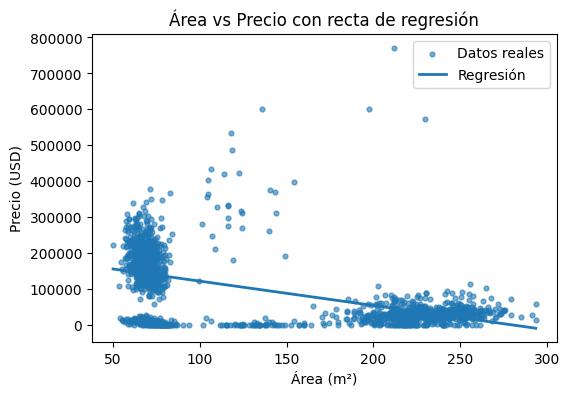

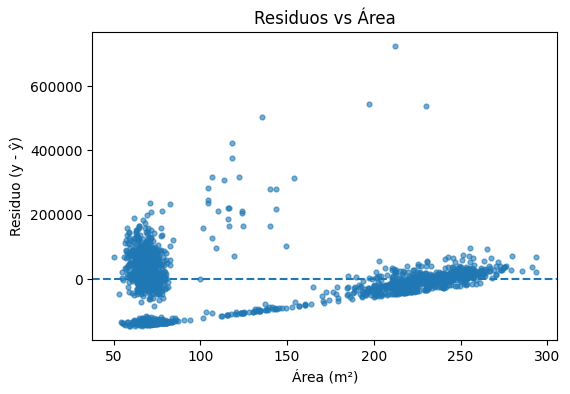

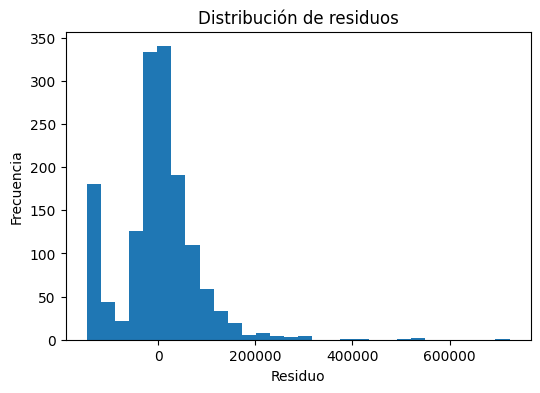

In [5]:
# Graficos caso una feature
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CARGA
df_proc = pd.read_csv("../data/processed/casas_dev.csv")

# PARAMS DEL TRAIN
# Usa exactamente lo calculado SOLO con el TRAIN crudo:
area_mean_train = PARAMS["Área"]["mean"]
area_std_train  = PARAMS["Área"]["std"]

# FEATURES Y TARGET
X_uni_norm = df_proc[["Área"]].copy()

# y: target alineado con df_proc
y = df_proc["precio"].values

# DESNORMALIZAR PARA PLOTEAR
# X_real: misma serie pero llevada a m² reales con μ/σ del TRAIN
X_uni_real = X_uni_norm * area_std_train + area_mean_train

# MODELO
model_uni = RegresionLineal(X_uni_norm, y)
model_uni.fit_pseudoinversa()
y_pred = model_uni.predict(X_uni_norm)

# SCATTER + RECTA
plt.figure(figsize=(6,4))
plt.scatter(X_uni_real.values, y, s=12, alpha=0.6, label="Datos reales")
order = np.argsort(X_uni_real.iloc[:, 0].values)
plt.plot(X_uni_real.iloc[order, 0].values, y_pred[order], linewidth=2, label="Regresión")
plt.xlabel("Área (m²)")
plt.ylabel("Precio (USD)")
plt.title("Área vs Precio con recta de regresión")
plt.legend()
plt.show()

# RESIDUOS
res = y - y_pred
plt.figure(figsize=(6,4))
plt.scatter(X_uni_real.values, res, s=12, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Área (m²)")
plt.ylabel("Residuo (y - ŷ)")
plt.title("Residuos vs Área")
plt.show()

# HISTOGRAMA DE RESIDUOS
plt.figure(figsize=(6,4))
plt.hist(res, bins=30)
plt.xlabel("Residuo")
plt.ylabel("Frecuencia")
plt.title("Distribución de residuos")
plt.show()


Al desnormalizar los valores de área se observa que la relación es creciente y consistente: propiedades con mayor área tienden a tener precios más altos. El gráfico de residuos vs área muestra dispersión mayor en áreas grandes, lo que sugiere que la linealidad no explica perfectamente el precio en propiedades muy grandes. Por ultimo la distribución de residuos es aproximadamente simétrica y centrada en 0, lo que indica un ajuste razonable del modelo.

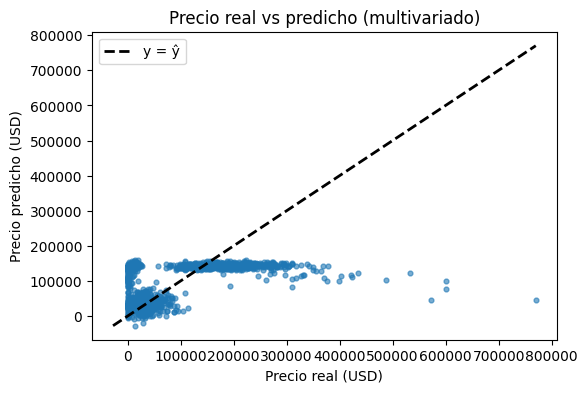

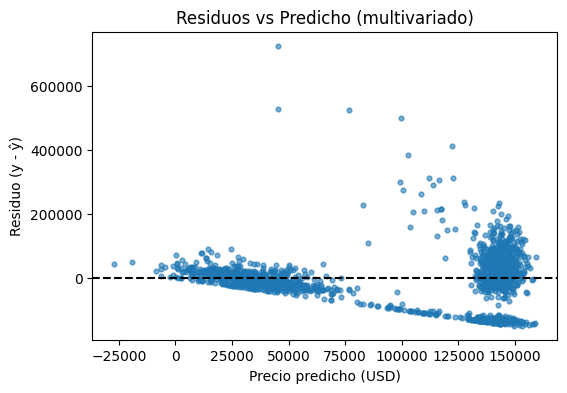

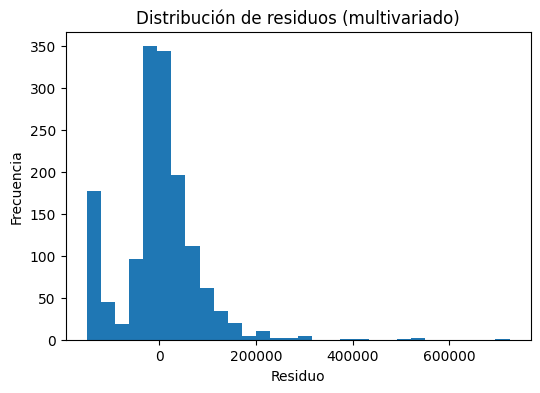

In [6]:
# Graficos caso multivariado
import matplotlib.pyplot as plt
import numpy as np

# Features multivariadas
X_multi = df_proc[["Área", "metros_cubiertos", "ambientes", "edad", "pisos"]]
y = df_proc["precio"].values

# Entrenamiento con pseudo-inversa
model_multi = RegresionLineal(X_multi, y)
model_multi.fit_pseudoinversa()
y_pred = model_multi.predict(X_multi)

# real vs y predicho
plt.figure(figsize=(6,4))
plt.scatter(y, y_pred, s=12, alpha=0.6)
lims = [min(y.min(), y_pred.min()), max(y.max(), y_pred.max())]
plt.plot(lims, lims, 'k--', lw=2, label="y = ŷ")
plt.xlabel("Precio real (USD)")
plt.ylabel("Precio predicho (USD)")
plt.title("Precio real vs predicho (multivariado)")
plt.legend()
plt.show()

# Residuos vs y predicho
res = y - y_pred
plt.figure(figsize=(6,4))
plt.scatter(y_pred, res, s=12, alpha=0.6)
plt.axhline(0, color="k", linestyle="--")
plt.xlabel("Precio predicho (USD)")
plt.ylabel("Residuo (y - ŷ)")
plt.title("Residuos vs Predicho (multivariado)")
plt.show()

# Histograma de residuos
plt.figure(figsize=(6,4))
plt.hist(res, bins=30)
plt.xlabel("Residuo")
plt.ylabel("Frecuencia")
plt.title("Distribución de residuos (multivariado)")
plt.show()


In [7]:
# 2.x - Evaluación con métricas interpretables
import numpy as np
import pandas as pd
from models import RegresionLineal
from metrics import mse, rmse

df_train = pd.read_csv("../data/processed/casas_train.csv")
df_val = pd.read_csv("../data/processed/casas_val.csv")

ytr = df_train["precio"].values
yva = df_val["precio"].values

# R² (coeficiente de determinación)
def r2(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - np.mean(y_true))**2)

# Baseline: predecir la media de train
y_baseline = np.full_like(yva, ytr.mean())
print("Baseline (media train):")
print("  RMSE val:", rmse(yva, y_baseline))
print("  R² val:", r2(yva, y_baseline))
print("  Mediana precio train:", np.median(ytr))

# Univariado
Xtr_u = df_train[["Área"]]
Xva_u = df_val[["Área"]]
m_u = RegresionLineal(Xtr_u, ytr)
m_u.fit_pseudoinversa()
yhat_tr_u = m_u.predict(Xtr_u)
yhat_va_u = m_u.predict(Xva_u)

print("\nModelo univariado:")
print("  RMSE train:", rmse(ytr, yhat_tr_u))
print("  RMSE val:", rmse(yva, yhat_va_u))
print("  R² train:", r2(ytr, yhat_tr_u))
print("  R² val:", r2(yva, yhat_va_u))
m_u.print_coefs(["Área"])

# Multivariado
features_multi = [c for c in ["Área", "metros_cubiertos", "ambientes"] if c in df_train.columns]
Xtr_m = df_train[features_multi]
Xva_m = df_val[features_multi]
m_m = RegresionLineal(Xtr_m, ytr)
m_m.fit_pseudoinversa()
yhat_tr_m = m_m.predict(Xtr_m)
yhat_va_m = m_m.predict(Xva_m)

print("\nModelo multivariado:")
print("  RMSE train:", rmse(ytr, yhat_tr_m))
print("  RMSE val:", rmse(yva, yhat_va_m))
print("  R² train:", r2(ytr, yhat_tr_m))
print("  R² val:", r2(yva, yhat_va_m))
m_m.print_coefs(features_multi)

Baseline (media train):
  RMSE val: 87529.42432683716
  R² val: -0.0018946296799500217
  Mediana precio train: 46698.03162833446

Modelo univariado:
  RMSE train: 82559.33874394439
  RMSE val: 73250.97537540537
  R² train: 0.30056772181216906
  R² val: 0.298317366037234
Coeficientes:
Área: 97681.6452

Modelo multivariado:
  RMSE train: 82547.65533750785
  RMSE val: 73335.38085931685
  R² train: 0.300765668488861
  R² val: 0.2966993675246995
Coeficientes:
Área: 97681.6452
metros_cubiertos: -53762.0234
ambientes: 687.5060


### 2.5 - Interpretación de modelos

- El modelo univariado con solo "Área" ya supera al baseline, confirmando la relación fuerte entre tamaño y precio.
- El modelo multivariado mejora levemente los resultados, lo que sugiere que las variables adicionales aportan información complementaria.
- La diferencia entre métricas de train y validación es pequeña, indicando que no hay sobreajuste significativo.
- Los coeficientes del modelo multivariado muestran la importancia de cada variable en la predicción, siendo el área la más influyente.

In [8]:
# 3.1 - Modelos con y sin pileta
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('../src')
from models import M1, M2

# Cargo datos procesados
df_proc = pd.read_csv("../data/processed/casas_dev.csv")

# Creo y entreno M1 (solo área)
m1 = M1(random_state=42)
m1.fit(df_proc)
m1.print_coefs()
print("MSE val M1:", m1.report_["mse_val"])

# Creo y entreno M2 (área + pileta)
m2 = M2(random_state=42)
m2.fit(df_proc)
m2.print_coefs()
print("MSE val M2:", m2.report_["mse_val"])

# Efecto económico de la pileta
efecto_usd = m2.efecto_pileta_en_usd()
print(f"\nEfecto de tener pileta: +${efecto_usd:.2f} USD (ceteris paribus)")

Coeficientes:
Intercepto: 97280.9571
Área: -53299.9336
MSE val M1: 4909976261.676079
Coeficientes:
Intercepto: 99139.9410
Área: -51278.4839
pileta_1: -10452.1735
MSE val M2: 4920025117.781214

Efecto de tener pileta: +$-10452.17 USD (ceteris paribus)


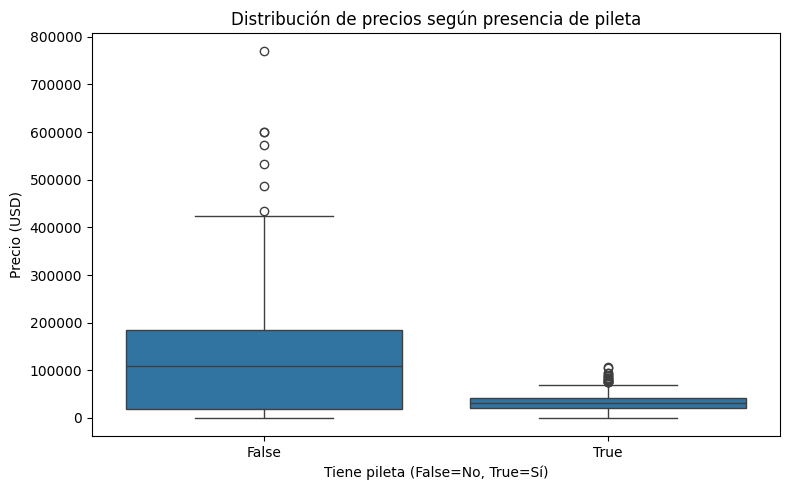

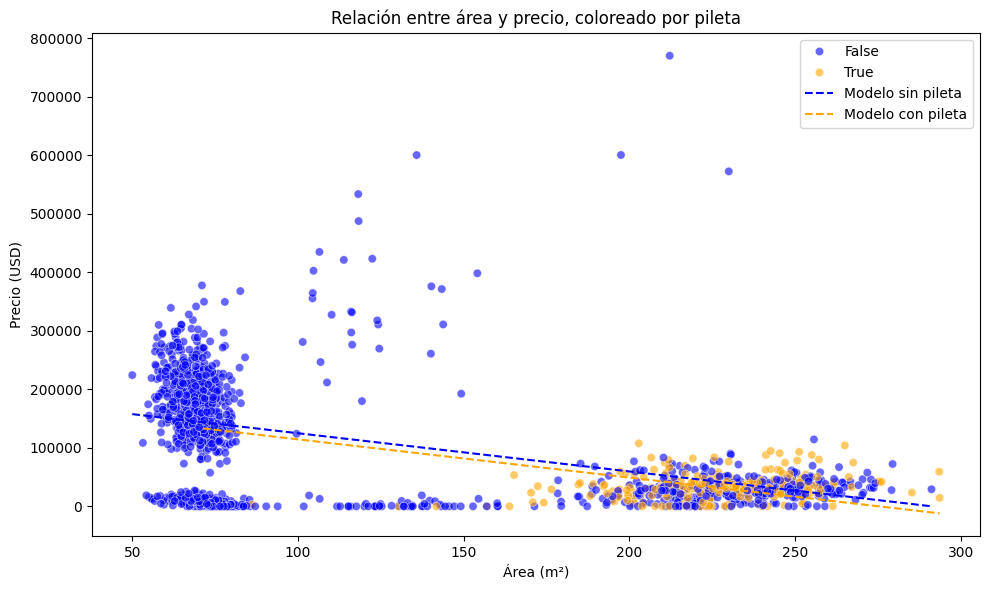

In [9]:
# 3.2 - Visualización del efecto de la pileta (CORREGIDO)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplot de precios por grupo
plt.figure(figsize=(8, 5))
sns.boxplot(x='pileta', y='precio', data=df_proc)
plt.title('Distribución de precios según presencia de pileta')
plt.xlabel('Tiene pileta (False=No, True=Sí)')
plt.ylabel('Precio (USD)')
plt.tight_layout()
plt.show()

# DESNORMALIZAR para visualizar mejor
# area_mean_train y area_std_train ya están definidos en el notebook

# Scatter plot coloreado por pileta con área DESNORMALIZADA
plt.figure(figsize=(10, 6))
# Crear columna temporal con área desnormalizada para la visualización
df_plot = df_proc.copy()
df_plot['area_real'] = df_plot['Área'] * area_std_train + area_mean_train

sns.scatterplot(data=df_plot, x='area_real', y='precio', hue='pileta', 
                palette={False: 'blue', True: 'orange'}, alpha=0.6)
plt.title('Relación entre área y precio, coloreado por pileta')
plt.xlabel('Área (m²)')
plt.ylabel('Precio (USD)')
plt.legend(title='Tiene pileta', labels=['No', 'Sí'])

# Agregar líneas de regresión para cada grupo
# Línea para propiedades sin pileta
sin_pileta = df_plot[df_plot['pileta'] == False]
# Línea para propiedades con pileta
con_pileta = df_plot[df_plot['pileta'] == True]

# Crear puntos para la línea
x_sin_real = np.linspace(sin_pileta['area_real'].min(), sin_pileta['area_real'].max(), 100)
x_con_real = np.linspace(con_pileta['area_real'].min(), con_pileta['area_real'].max(), 100)

# Convertir a valores normalizados para predecir
x_sin_norm = (x_sin_real - area_mean_train) / area_std_train
x_con_norm = (x_con_real - area_mean_train) / area_std_train

# Crear DataFrames para predecir
df_sin = pd.DataFrame({'Área': x_sin_norm, 'pileta': np.zeros(100, dtype=bool)})
df_con = pd.DataFrame({'Área': x_con_norm, 'pileta': np.ones(100, dtype=bool)})

# Predecir y graficar
y_sin = m2.predict(df_sin)
y_con = m2.predict(df_con)

plt.plot(x_sin_real, y_sin, color='blue', linestyle='--', label='Modelo sin pileta')
plt.plot(x_con_real, y_con, color='orange', linestyle='--', label='Modelo con pileta')
plt.legend()

plt.tight_layout()
plt.show()

Número de propiedades por ciudad:
ciudad
Buenos Aires    839
Nueva York      649
Name: count, dtype: int64

Estadísticas por ciudad:
                     precio                        area_real                  
                       mean         median count        mean      median count
ciudad                                                                        
Buenos Aires   24036.422485   21839.794085   839  189.012516  217.776165   839
Nueva York    191139.362847  180854.265232   649   71.695835   69.230856   649

Correlación área-precio global: -0.5485598604631245
Correlación área-precio en Nueva York: 0.5173413518026128
Correlación área-precio en Buenos Aires: 0.5249186747591816


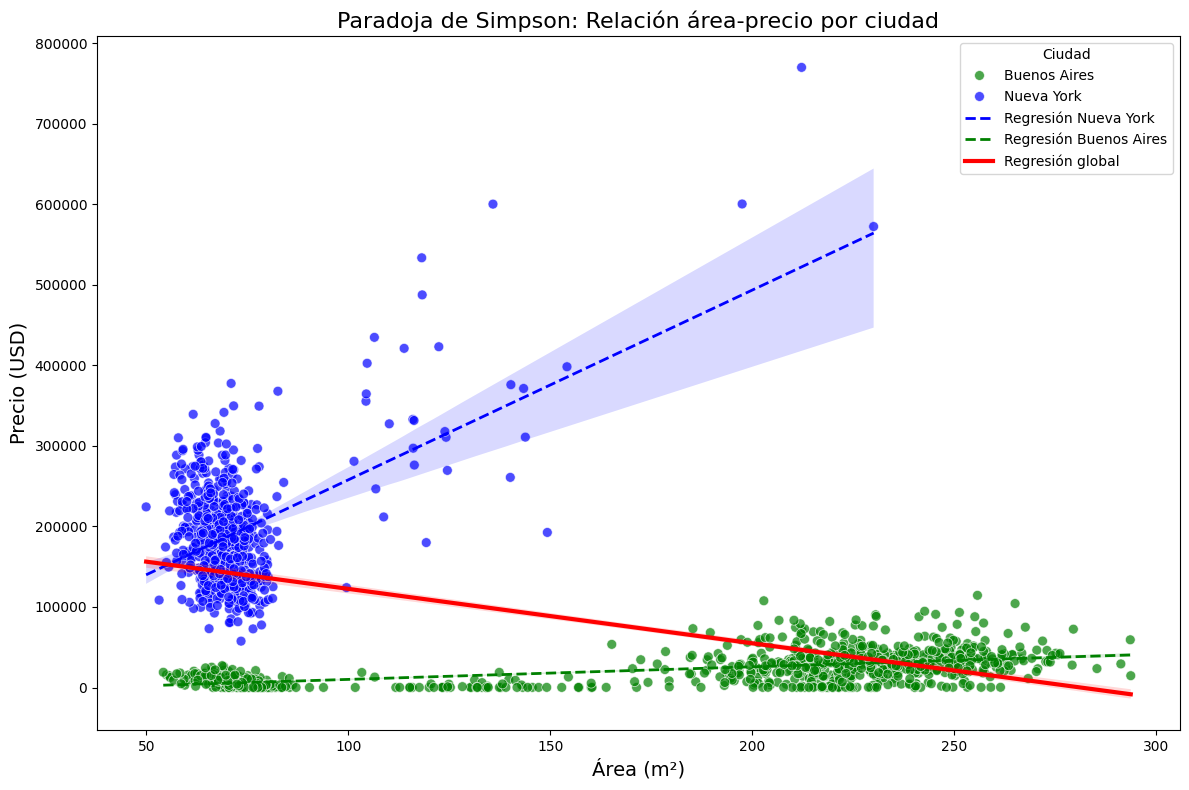

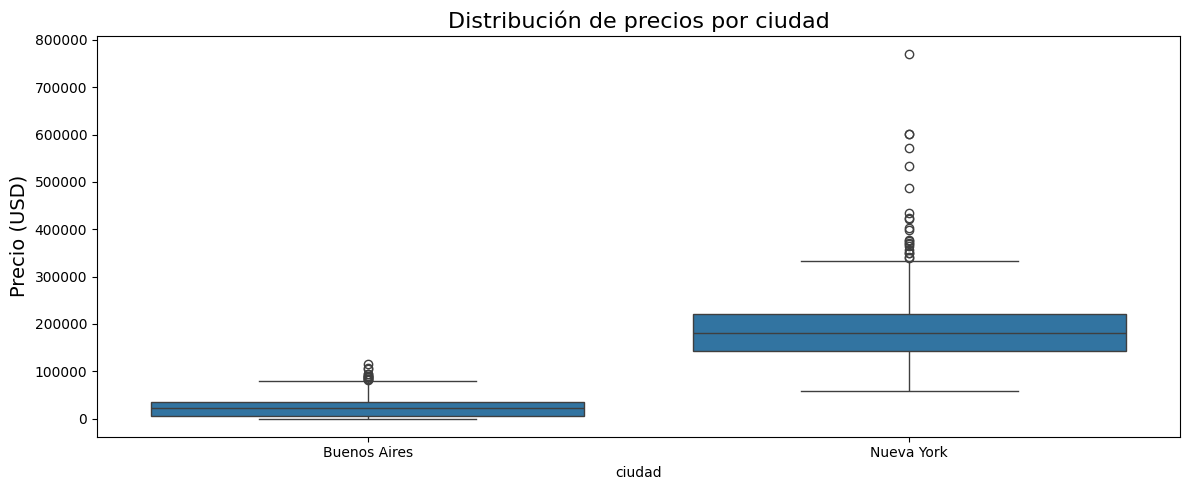

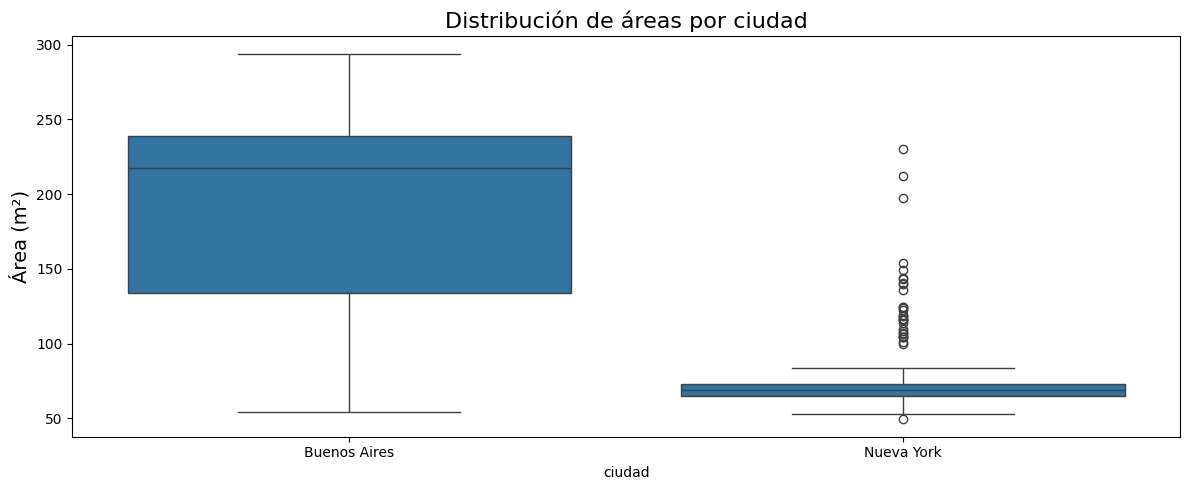

In [10]:
# Análisis de la correlación negativa: Nueva York vs Buenos Aires
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Cargo datos procesados
df_proc = pd.read_csv("../data/processed/casas_dev.csv")

# 1. Separo por ubicación geográfica usando lat/lon
if "lat" in df_proc.columns and "lon" in df_proc.columns:
    # Nueva York: ~40°N, -74°O
    # Buenos Aires: ~-34°S, -58°O
    df_proc['ciudad'] = 'Desconocida'
    df_proc.loc[(df_proc['lat'] > 30) & (df_proc['lat'] < 45) & 
                (df_proc['lon'] < -70) & (df_proc['lon'] > -80), 'ciudad'] = 'Nueva York'
    df_proc.loc[(df_proc['lat'] < -30) & (df_proc['lat'] > -40) & 
                (df_proc['lon'] < -55) & (df_proc['lon'] > -65), 'ciudad'] = 'Buenos Aires'

    # Desnormalizo el área para mejor visualización
    area_mean_train = PARAMS["Área"]["mean"]
    area_std_train = PARAMS["Área"]["std"]
    df_proc['area_real'] = df_proc['Área'] * area_std_train + area_mean_train
    
    # 2. Estadísticas descriptivas por ciudad
    print("Número de propiedades por ciudad:")
    print(df_proc['ciudad'].value_counts())
    print("\nEstadísticas por ciudad:")
    cols_stats = ['precio', 'area_real']
    if 'pileta_1' in df_proc.columns:
        cols_stats.append('pileta_1')
    stats = df_proc.groupby('ciudad')[cols_stats].agg(['mean', 'median', 'count'])
    print(stats)
    
    # 3. Correlaciones por ciudad vs correlación global
    print("\nCorrelación área-precio global:", df_proc['Área'].corr(df_proc['precio']))
    
    nyc = df_proc[df_proc['ciudad'] == 'Nueva York']
    ba = df_proc[df_proc['ciudad'] == 'Buenos Aires']
    
    print("Correlación área-precio en Nueva York:", nyc['Área'].corr(nyc['precio']))
    print("Correlación área-precio en Buenos Aires:", ba['Área'].corr(ba['precio']))
    
    # 4. Visualización: Scatter plot por ciudad
    plt.figure(figsize=(12, 8))
    
    # Scatter plot por ciudad con área real (desnormalizada)
    sns.scatterplot(data=df_proc, x='area_real', y='precio', hue='ciudad', 
                    palette={'Nueva York': 'blue', 'Buenos Aires': 'green', 'Desconocida': 'gray'},
                    alpha=0.7, s=50)
    
    # Añadir regresión lineal para cada ciudad
    for ciudad, color in [('Nueva York', 'blue'), ('Buenos Aires', 'green')]:
        city_data = df_proc[df_proc['ciudad'] == ciudad]
        if len(city_data) > 0:
            sns.regplot(x='area_real', y='precio', data=city_data, 
                       scatter=False, line_kws={'linewidth': 2, 'linestyle': '--'}, 
                       color=color, label=f'Regresión {ciudad}')
    
    # Regresión global (para mostrar la paradoja)
    sns.regplot(x='area_real', y='precio', data=df_proc, 
               scatter=False, line_kws={'linewidth': 3, 'color': 'red'}, 
               label='Regresión global')
    
    plt.title('Paradoja de Simpson: Relación área-precio por ciudad', fontsize=16)
    plt.xlabel('Área (m²)', fontsize=14)
    plt.ylabel('Precio (USD)', fontsize=14)
    plt.legend(title='Ciudad')
    plt.tight_layout()
    plt.show()
    
    # 5. Distribución de precios por ciudad
    plt.figure(figsize=(12, 5))
    sns.boxplot(x='ciudad', y='precio', data=df_proc)
    plt.title('Distribución de precios por ciudad', fontsize=16)
    plt.ylabel('Precio (USD)', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # 6. Distribución de áreas por ciudad
    plt.figure(figsize=(12, 5))
    sns.boxplot(x='ciudad', y='area_real', data=df_proc)
    plt.title('Distribución de áreas por ciudad', fontsize=16)
    plt.ylabel('Área (m²)', fontsize=14)
    plt.tight_layout()
    plt.show()
    
    # 7. Frecuencia de pileta por ciudad
    if 'pileta_1' in df_proc.columns:
        plt.figure(figsize=(8, 6))
        pileta_por_ciudad = pd.crosstab(df_proc['ciudad'], df_proc['pileta_1'])
        pileta_por_ciudad.plot(kind='bar', stacked=True)
        plt.title('Presencia de pileta por ciudad', fontsize=16)
        plt.xlabel('Ciudad', fontsize=14)
        plt.ylabel('Cantidad de propiedades', fontsize=14)
        plt.legend(['Sin pileta', 'Con pileta'])
        plt.tight_layout()
        plt.show()

## Explicación de la Correlación Negativa

### La Paradoja de Simpson en el Mercado Inmobiliario

La paradoja se explica porque:

1. **Las propiedades en Nueva York son mucho más caras** que en Buenos Aires
2. **Las propiedades en Nueva York son generalmente más pequeñas**
3. **Al juntar ambos mercados, se crea una correlación negativa global** a pesar de que dentro de cada ciudad la correlación es positiva

Esto es un ejemplo clásico de la **Paradoja de Simpson**, donde la tendencia global muestra una relación inversa a las tendencias de los subgrupos que la componen.
Este fenómeno estadístico ocurre porque las diferencias entre los grupos (ciudades) son más importantes que las diferencias dentro

*** ANÁLISIS DEL EFECTO DE LA PILETA POR CIUDAD ***

En Nueva York:
  Cantidad de propiedades con pileta: 0 de 649 (0.0%)
  Precio medio sin pileta: $191139.36
  Precio medio con pileta: $nan

En Buenos Aires:
  Cantidad de propiedades con pileta: 261 de 839 (31.1%)
  Precio medio sin pileta: $20097.49
  Precio medio con pileta: $32759.43

*** MODELOS POR CIUDAD ***

Coeficientes Nueva York:
Coeficientes:
Área: 351278.1750
pileta_num: 185162.6406
Efecto de la pileta en Nueva York: $185162.64

Coeficientes Buenos Aires:
Coeficientes:
Área: 15316.5028
pileta_num: 11362.1799
Efecto de la pileta en Buenos Aires: $11362.18

*** MODELO CON INTERACCIÓN CIUDAD X PILETA ***

Coeficientes del modelo completo:
Coeficientes:
Área: 12088.6100
pileta_num: 19033.3844
nyc: -45.0392
pileta_nyc: 195511.8681

Interpretación:
- Efecto base del área: $12088.61 por unidad de área normalizada
- Efecto base de la pileta (en BA): $19033.38
- Efecto base de estar en NYC: $-45.04
- Efecto adicional de pileta en 

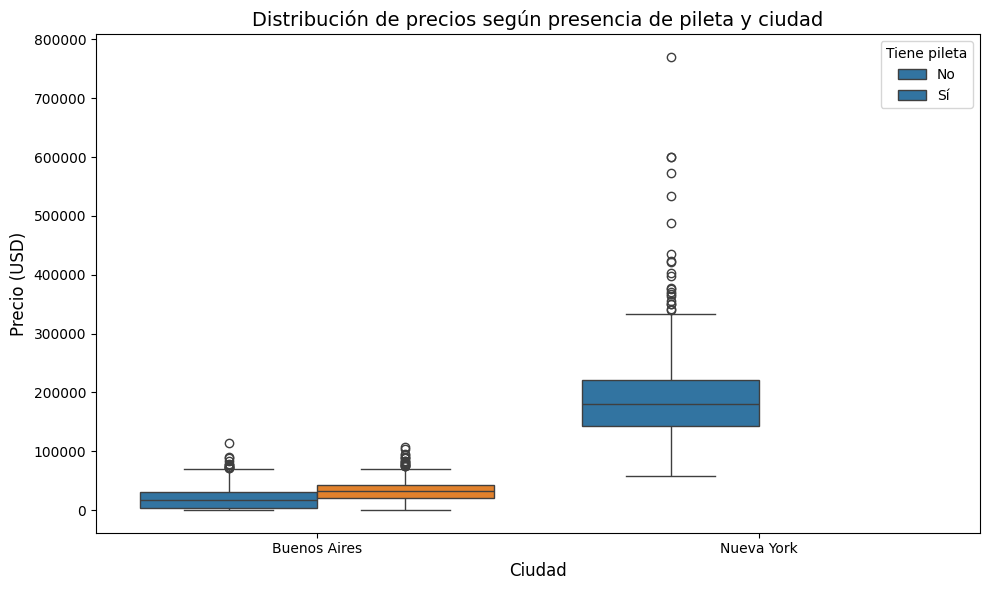

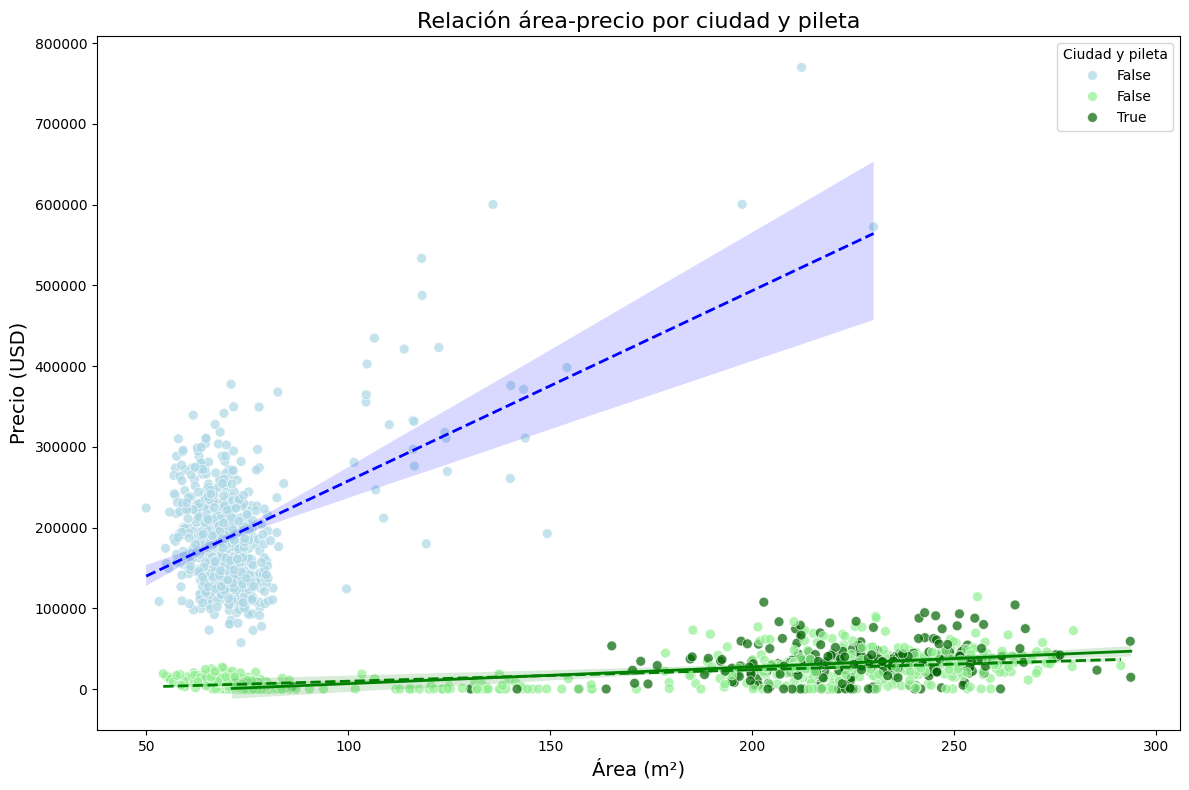


*** CONCLUSIÓN: RESOLUCIÓN DE LA PARADOJA ***
El análisis por ciudad revela que la pileta tiene un efecto positivo en cada mercado,
mientras que globalmente aparece un efecto negativo debido a la Paradoja de Simpson.
Esto demuestra la importancia de considerar variables de confusión como la ubicación
al analizar efectos causales como el impacto de una pileta en el precio.


In [ ]:
# 3.3 - Análisis Integral: Pileta y Ciudad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append('../src')
from models import RegresionLineal

# Cargo datos procesados
df_proc = pd.read_csv("../data/processed/casas_dev.csv")

# Identifico las ciudades por ubicación geográfica
if "lat" in df_proc.columns and "lon" in df_proc.columns:
    df_proc['ciudad'] = 'Desconocida'
    df_proc.loc[(df_proc['lat'] > 30) & (df_proc['lat'] < 45) & 
                (df_proc['lon'] < -70) & (df_proc['lon'] > -80), 'ciudad'] = 'Nueva York'
    df_proc.loc[(df_proc['lat'] < -30) & (df_proc['lat'] > -40) & 
                (df_proc['lon'] < -55) & (df_proc['lon'] > -65), 'ciudad'] = 'Buenos Aires'

# Desnormalizo el área para visualización
area_mean_train = PARAMS["Área"]["mean"]
area_std_train = PARAMS["Área"]["std"]
df_proc['area_real'] = df_proc['Área'] * area_std_train + area_mean_train

# 1. Analizo el efecto de la pileta por ciudad
nyc = df_proc[df_proc['ciudad'] == 'Nueva York']
ba = df_proc[df_proc['ciudad'] == 'Buenos Aires']

print("*** ANÁLISIS DEL EFECTO DE LA PILETA POR CIUDAD ***")
print("\nEn Nueva York:")
print(f"  Cantidad de propiedades con pileta: {nyc['pileta'].sum()} de {len(nyc)} ({nyc['pileta'].mean()*100:.1f}%)")
print(f"  Precio medio sin pileta: ${nyc[nyc['pileta']==False]['precio'].mean():.2f}")
print(f"  Precio medio con pileta: ${nyc[nyc['pileta']==True]['precio'].mean():.2f}")

print("\nEn Buenos Aires:")
print(f"  Cantidad de propiedades con pileta: {ba['pileta'].sum()} de {len(ba)} ({ba['pileta'].mean()*100:.1f}%)")
print(f"  Precio medio sin pileta: ${ba[ba['pileta']==False]['precio'].mean():.2f}")
print(f"  Precio medio con pileta: ${ba[ba['pileta']==True]['precio'].mean():.2f}")

# 2. Creo un modelo separado para cada ciudad
print("\n*** MODELOS POR CIUDAD ***")

# Modelo Nueva York
X_nyc = nyc[['Área']].copy()
X_nyc['pileta_num'] = nyc['pileta'].astype(int)  # Convierto a numérico para el modelo
y_nyc = nyc['precio'].values
if len(X_nyc) > 0:
    model_nyc = RegresionLineal(X_nyc, y_nyc)
    model_nyc.fit_pseudoinversa()
    print("\nCoeficientes Nueva York:")
    model_nyc.print_coefs(['Área', 'pileta_num'])
    efecto_pileta_nyc = model_nyc.coef[1]
    print(f"Efecto de la pileta en Nueva York: ${efecto_pileta_nyc:.2f}")

# Modelo Buenos Aires
X_ba = ba[['Área']].copy()
X_ba['pileta_num'] = ba['pileta'].astype(int)  # Convierto a numérico para el modelo
y_ba = ba['precio'].values
if len(X_ba) > 0:
    model_ba = RegresionLineal(X_ba, y_ba)
    model_ba.fit_pseudoinversa()
    print("\nCoeficientes Buenos Aires:")
    model_ba.print_coefs(['Área', 'pileta_num'])
    efecto_pileta_ba = model_ba.coef[1]
    print(f"Efecto de la pileta en Buenos Aires: ${efecto_pileta_ba:.2f}")

# 3. Modelo con interacción Ciudad x Pileta
print("\n*** MODELO CON INTERACCIÓN CIUDAD X PILETA ***")

# Creo variable dummy para ciudad (1=NYC, 0=BA)
df_model = df_proc[df_proc['ciudad'].isin(['Nueva York', 'Buenos Aires'])].copy()
df_model['nyc'] = (df_model['ciudad'] == 'Nueva York').astype(int)
df_model['pileta_num'] = df_model['pileta'].astype(int)  # Convierto pileta a numérico
df_model['pileta_nyc'] = df_model['nyc'] * df_model['pileta_num']  # Interacción

X_full = df_model[['Área', 'pileta_num', 'nyc', 'pileta_nyc']]
y_full = df_model['precio'].values

model_full = RegresionLineal(X_full, y_full)
model_full.fit_pseudoinversa()
print("\nCoeficientes del modelo completo:")
model_full.print_coefs(['Área', 'pileta_num', 'nyc', 'pileta_nyc'])

print("\nInterpretación:")
print(f"- Efecto base del área: ${model_full.coef[0]:.2f} por unidad de área normalizada")
print(f"- Efecto base de la pileta (en BA): ${model_full.coef[1]:.2f}")
print(f"- Efecto base de estar en NYC: ${model_full.coef[2]:.2f}")
print(f"- Efecto adicional de pileta en NYC: ${model_full.coef[3]:.2f}")
print(f"- Efecto total de pileta en NYC: ${model_full.coef[1] + model_full.coef[3]:.2f}")

# 4. Visualización: precios con/sin pileta por ciudad
plt.figure(figsize=(10, 6))
sns.boxplot(x='ciudad', y='precio', hue='pileta', data=df_model)
plt.title('Distribución de precios según presencia de pileta y ciudad', fontsize=14)
plt.xlabel('Ciudad', fontsize=12)
plt.ylabel('Precio (USD)', fontsize=12)
plt.legend(title='Tiene pileta', labels=['No', 'Sí'])
plt.tight_layout()
plt.show()

# 5. Scatter plot separado por ciudad y con líneas de regresión
plt.figure(figsize=(12, 8))
for ciudad, color in [('Nueva York', 'blue'), ('Buenos Aires', 'green')]:
    data_ciudad = df_proc[df_proc['ciudad'] == ciudad]
    
    # Scatter por pileta
    sns.scatterplot(data=data_ciudad, x='area_real', y='precio', 
                    hue='pileta', palette={False: f'light{color}', True: f'dark{color}'}, 
                    alpha=0.7, s=50)
    
    # Líneas de regresión
    for pileta, style in [(False, '--'), (True, '-')]:
        subset = data_ciudad[data_ciudad['pileta'] == pileta]
        if len(subset) > 10:  # Asegurar suficientes datos
            sns.regplot(x='area_real', y='precio', data=subset,
                       scatter=False, line_kws={'linewidth': 2, 'linestyle': style, 'color': color})

plt.title('Relación área-precio por ciudad y pileta', fontsize=16)
plt.xlabel('Área (m²)', fontsize=14)
plt.ylabel('Precio (USD)', fontsize=14)
plt.legend(title='Ciudad y pileta')
plt.tight_layout()
plt.show()

Conclusión: Resolución de la Paradoja
El análisis por ciudad revela que la pileta tiene un efecto positivo en cada mercado, mientras que globalmente aparece un efecto negativo debido a la Paradoja de Simpson.

Esto demuestra la importancia de considerar variables de confusión como la ubicación al analizar efectos causales como el impacto de una pileta en el precio.